# 01 - Metadata & Inventory

Characterising the FRB dataset from metadata alone. No bulk data gets read here. The `.fil` is 2 GB, so I only touched the header.

**Inputs**
`CUT_P_110_inj_13_processed.fil` (header only), `CUT_P_110_inj_params.csv`, and the full candmaker output directory: 102 `.h5` candidates, `Results_MULTI.csv`, `results_a..k.csv`, the Heimdall `.cand` files, `all_candidates.csv` and the candmaker log.

**Goals for this Notebook**
1. Get the real instrument parameters and verify them against the raw header.
2. Which injections did Heimdall+FETCH recover, and if any were missed, why?
3. Where the injections sit against the instrument's own smearing and boxcar limits.
4. Which metadata columns are usable as features, and which are constant or absent.
5. Build ground-truth labels, because nothing the pipeline outputs is truth.

**Environment**: Python 3.14 with the packages in the README. Paths, worker count and the random seed all come from `frb_eda/config.py`, which reads environment variables (`FRB_ROOT`, `FRB_CAND_DIR`, `FRB_FIL`, `FRB_INJ_CSV`, `FRB_OUT`, `FRB_N_JOBS`, `FRB_SEED`), so nothing here hardcodes a drive letter. Functions that more than one notebook uses live in `frb_eda/` so there is one copy of each.

## Configuration

In [1]:
import sys
from pathlib import Path
CODE_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "frb_eda").is_dir())
sys.path.insert(0, str(CODE_ROOT))

from pprint import pprint
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from frb_eda import axes as h5axes, config, provenance, sigproc
from frb_eda.physics import K_DM, dm_delay_s, dm_smear_chan_s, w_eff_s

CAND_DIR = config.CAND_DIR
OUT_DIR  = config.out_dir("nb01")

def _one(d, pattern, required=True):
    hits = sorted(d.glob(pattern))
    if len(hits) == 1: return hits[0]
    if not hits and not required: return None
    raise FileNotFoundError(f"{d}: {pattern!r} matched {len(hits)}: {[h.name for h in hits]}")

FIL_PATH   = config.FIL_PATH
INJ_CSV    = config.INJ_CSV
SEARCH_TXT = CAND_DIR / "Search_parameters.txt"
RESULTS_MULTI = CAND_DIR / "Results_MULTI.csv"
BEST_CSV      = CAND_DIR / "Best_candidates.csv"
ALL_CAND_CSV  = _one(CAND_DIR, "*_all_candidates.csv")
ALL_CAND_DOT  = _one(CAND_DIR, "*_all.cand")
GULP_CANDS    = sorted(CAND_DIR.glob("*_01.cand"))
MODEL_CSVS    = sorted(CAND_DIR.glob("results_?.csv"))
CANDMAKER_LOG = _one(CAND_DIR, "your_candmaker_*.log", required=False)
H5_FILES      = sorted(CAND_DIR.glob("cand_tstart_*.h5"))

SENTINEL   = -999.0
BOXCAR_MAX = 1024
DM_LOW, DM_MAX, DM_TOL = 10.0, 3000.0, 1.01
TOL_T_S, TOL_DM_FR = 0.50, 0.10

plt.rcParams.update({"figure.dpi":120,"figure.figsize":(9.0,4.5),"font.size":9,
                     "axes.grid":True,"grid.alpha":0.30,"axes.axisbelow":True})
pd.set_option("display.width",200); pd.set_option("display.max_columns",50)
for p in [FIL_PATH, INJ_CSV, SEARCH_TXT, RESULTS_MULTI, BEST_CSV, ALL_CAND_CSV, ALL_CAND_DOT, CANDMAKER_LOG]:
    if p is None: continue
    print(f"{p.name[:46]:46} {p.stat().st_size:>14,}" if p.exists() else f"{p.name[:46]:46} {'MISSING':>14}")
print(f"\ngulps={len(GULP_CANDS)} models={len(MODEL_CSVS)} h5={len(H5_FILES)}")
print("outputs ->", OUT_DIR)
print("config  ->", config.describe())

CUT_P_110_inj_13_processed.fil                  2,074,550,599
CUT_P_110_inj_params.csv                                1,771
Search_parameters.txt                                   1,234
Results_MULTI.csv                                      17,459
Best_candidates.csv                                     2,069
2024-02-16-18-12-59_all_candidates.csv                 10,511
2024-02-16-18-12-59_all.cand                            7,374
your_candmaker_2025_01_30_12_55_27_273506.log      16,083,191

gulps=4 models=11 h5=102
outputs -> C:\Users\Hans\OneDrive\Documents\QML\FRB Data\frb_analysis_out\nb01
config  -> {'ROOT': 'C:\\Users\\Hans\\OneDrive\\Documents\\QML\\FRB Data', 'CAND_DIR': 'C:\\Users\\Hans\\OneDrive\\Documents\\QML\\FRB Data\\CUT_P_110_inj_13_processed_2025-1-30-13-51', 'FIL_PATH': 'C:\\Users\\Hans\\OneDrive\\Documents\\QML\\FRB Data\\Data\\CUT_P_110_inj_13_processed.fil', 'INJ_CSV': 'C:\\Users\\Hans\\OneDrive\\Documents\\QML\\FRB Data\\Data\\CUT_P_110_inj_params.csv', 'OUT_ROOT'

## SIGPROC (Signal Processing Tools) header parser

### Why
`your` and `sigpyproc` can both read `.fil` perfectly well, but parsing the bytes means you (a) stay on numpy/pandas only, (b) get the exact **data start offset** that nb03's
memmap needs, and (c) verify the header rather than trusting `Search_parameters.txt`. See the notes further down about how much of the pipeline's own bookkeeping is stale.

### Layout
Header, then raw samples.

    [ header · 327 bytes ][ data · 2,074,550,272 bytes ]

Data is **time-major**: all channels for t0, then all for t1, and so on. Channel `i` is at `fch1 + i*foff`, and `foff` is negative, so the **band runs downward** from 415.85 MHz.

Each header entry is `[int32 keylen][keyword][value]`:

    offset 233:  06 00 00 00  "nchans"  00 04 00 00   → 1024

### Flow
1. `_lenstr()` reads an int32 count, then that many ASCII bytes.
2. The first one has to be `"HEADER_START"`.
3. Loop keywords until `"HEADER_END"`, consuming the right width for each type.
4. `f.tell()` then sits on the first data byte → `_header_bytes`.

### Guards
- `0 <= n <= 80` in `_lenstr` is the desync tripwire. If a width is misjudged the position slips, the next "length" is junk, and without this check Python attempts a multi-GB read and hangs.
- `data_bytes % (nchans*itemsize) == 0` catches a truncated file or a wrong layout assumption.

### What this feeds
    _header_bytes  → memmap offset
    nchans, nbits  → memmap shape + dtype
    fch1, foff     → freq axis, DM delays
    tsamp          → time axis, boxcar ms

In [2]:
# The parser is in frb_eda/sigproc.py so nb01 and nb03 share one copy. It is the
# same code as described above: _lenstr with the 0..80 tripwire, a keyword->type
# table, and _header_bytes taken from f.tell() at HEADER_END.
from frb_eda.sigproc import read_sigproc_header, sigproc_angle_to_deg, SIGPROC_TYPES

hdr = read_sigproc_header(FIL_PATH)
pprint(hdr)

{'_header_bytes': 327,
 'az_start': 1.0,
 'data_type': 1,
 'fch1': 415.85445601851853,
 'foff': -0.014467592592592591,
 'ibeam': 1,
 'machine_id': 1,
 'nbeams': 1,
 'nbits': 16,
 'nchans': 1024,
 'nifs': 1,
 'source_name': 'SGR0501+4516',
 'src_dej': 451634.0,
 'src_raj': 50106.8,
 'telescope_id': 30,
 'tsamp': 0.00013824,
 'tstart': 60356.79948498255,
 'za_start': 1.0}


### What each header field means

Values below are from `CUT_P_110_inj_13_processed.fil`.

#### Frequency axis
| key | value | meaning |
|---|---|---|
| `fch1` | 415.85446 | centre freq of **channel 0**, MHz |
| `foff` | −0.01446759 | channel spacing, MHz. **Negative → band descends** |
| `nchans` | 1024 | number of channels |

    freqs = fch1 + foff * arange(nchans)   →  415.854 down to 401.054 MHz
    bandwidth = |foff| * nchans = 14.8148 MHz
    centre    = 408.4543 MHz     (matches the .h5 center_freq, which is reassuring)

#### Time axis
| key | value | meaning |
|---|---|---|
| `tsamp` | 0.00013824 | sample interval, s = **138.24 µs** |
| `tstart` | 60356.79948 | observation start, **MJD** |

`tsamp` also sets the boxcar scale: Heimdall's `BOXCAR_MAX=1024` works out to a 141.6 ms
ceiling, which becomes relevant when we get to the injection it rejected.

#### Data shape
| key | value | meaning |
|---|---|---|
| `nbits` | 16 | bits per sample → 2 bytes, `uint16` |
| `nifs` | 1 | polarisation products. 1 = total intensity |
| `data_type` | 1 | 1 = filterbank (raw channels). 2 would be a dedispersed time series |
| `_header_bytes` | 327 | not a SIGPROC key, it's where the data starts |

`nifs > 1` would interleave polarisations and break the simple `(nsamp, nchans)` reshape.

#### Pointing / identity
| key | value | meaning |
|---|---|---|
| `source_name` | SGR0501+4516 | what the dish was pointed at |
| `src_raj` | 50106.8 | RA as packed digits |
| `src_dej` | 451634.0 | Dec as packed digits |
| `nbeams` / `ibeam` | 1 / 1 | one beam, and this is beam 1 |
| `telescope_id` | 30 | local Medicina assignment |
| `machine_id` | 1 | backend/recorder ID |

#### Junk
| key | value | meaning |
|---|---|---|
| `az_start` | 1.0 | azimuth placeholder |
| `za_start` | 1.0 | zenith angle placeholder |

## Instrument constants

### Why
The header gives raw keywords. This turns them into the numbers we'll use, and
checks them against the file size *before* nb03 memmaps 2 GB on trust.

### File size check

    data_bytes = filesize - 327
    nsamples   = data_bytes / (nchans * itemsize)

If that division doesn't come out exact then the layout assumption is wrong and nothing
downstream is safe.

Two things this header doesn't have: no `nsamples` key, so we derive it from the file size,
and no `signed` key, so `uint16` is an assumption.
nb03 checks the second one by looking for wraparound.

In [3]:
nchans = int(hdr["nchans"]); nbits = int(hdr["nbits"]); tsamp = float(hdr["tsamp"])
fch1 = float(hdr["fch1"]); foff = float(hdr["foff"]); hdr_bytes = int(hdr["_header_bytes"])
itemsize = nbits // 8

file_bytes = FIL_PATH.stat().st_size
data_bytes = file_bytes - hdr_bytes
nsamp_file = data_bytes // (nchans * itemsize)

freqs = fch1 + foff * np.arange(nchans)
f_hi, f_lo = float(freqs.max()), float(freqs.min())
f_ctr = 0.5 * (f_hi + f_lo)
bw = abs(foff) * nchans
duration = nsamp_file * tsamp

# the memmap contract for nb03: if this trips, do not proceed
assert data_bytes % (nchans * itemsize) == 0, "data size not divisible by spectrum size"
if "nsamples" in hdr:
    assert int(hdr["nsamples"]) == nsamp_file, f"header {hdr['nsamples']} != {nsamp_file}"
else:
    print("note: header has no 'nsamples' -> derived from file size")
if "signed" not in hdr:
    print(f"note: header has no 'signed' -> assuming uint{nbits} (verify in nb03)")

INSTR = {
    "source_name": hdr.get("source_name", "?").strip(),
    "ra_deg":  sigproc_angle_to_deg(hdr["src_raj"], True),
    "dec_deg": sigproc_angle_to_deg(hdr["src_dej"], False),
    "mjd_start": float(hdr["tstart"]),
    "nchans": nchans, "nbits": nbits, "itemsize_bytes": itemsize,
    "tsamp_s": tsamp, "tsamp_us": tsamp * 1e6,
    "fch1_MHz": fch1, "foff_MHz": foff,
    "f_hi_MHz": f_hi, "f_lo_MHz": f_lo, "f_ctr_MHz": f_ctr,
    "bandwidth_MHz": bw, "header_bytes": hdr_bytes,
    "nsamples": int(nsamp_file), "duration_s": duration,
    "band_descending": foff < 0,
}
display(pd.Series(INSTR, name="value").to_frame())
print(f"\nmemmap: offset={hdr_bytes} shape=({nsamp_file},{nchans}) dtype=uint{nbits}")
print(f"band {f_lo:.3f}-{f_hi:.3f} MHz ({bw:.3f} MHz)  duration {duration:.2f} s")

note: header has no 'nsamples' -> derived from file size
note: header has no 'signed' -> assuming uint16 (verify in nb03)


,value
source_name,SGR0501+4516
ra_deg,75.278333
dec_deg,45.276111
mjd_start,60356.799485
nchans,1024
nbits,16
itemsize_bytes,2
tsamp_s,0.000138
tsamp_us,138.24
fch1_MHz,415.854456



memmap: offset=327 shape=(1012964,1024) dtype=uint16
band 401.054-415.854 MHz (14.815 MHz)  duration 140.03 s


## Dispersion physics

Three quantities, all out of the cold-plasma law `K_DM = 4.148808e3`.

| function | what it gives | meaning |
|---|---|---|
| `dm_delay_s` | sweep across the whole band | how wide a chunk has to be to hold the pulse |
| `dm_smear_chan_s` | smearing inside one channel | the width floor |
| `w_eff_s` | observed width | intrinsic, smear and `tsamp` added in quadrature |

At 400 MHz this bites. DM 3000 sweeps **5.4 s** across the band and smears **5.3 ms** inside a single channel, which is 38 samples. So at high DM the observed width is mostly
instrument.

Width is partly a DM proxy and that correlation is instrumental, so keep it in mind when treating width as a feature.

In [4]:
# dm_delay_s, dm_smear_chan_s and w_eff_s are imported from frb_eda/physics.py in the
# config cell, so nb01 and nb04 use the same definitions.
for dm_ in (DM_LOW, 530.0, DM_MAX):
    print(f"DM {dm_:7.1f} sweep={dm_delay_s(dm_, f_hi, f_lo):7.3f}s "
          f"smear={dm_smear_chan_s(dm_, f_ctr, foff) * 1e3:7.3f}ms "
          f"({dm_smear_chan_s(dm_, f_ctr, foff) / tsamp:7.2f} samp)")

DM    10.0 sweep=  0.018s smear=  0.018ms (   0.13 samp)
DM   530.0 sweep=  0.956s smear=  0.934ms (   6.75 samp)
DM  3000.0 sweep=  5.410s smear=  5.285ms (  38.23 samp)


## Injection ground truth

13 injections. Everything else, Heimdall's candidates and FETCH's labels included, is something the pipeline decided.

`-999.0` is the sentinel for "not set", so swap it for NaN and see which columns survive.

In [5]:
inj = pd.read_csv(INJ_CSV).replace(SENTINEL, np.nan)
col_report = pd.DataFrame({"dtype":inj.dtypes.astype(str),"n_present":inj.notna().sum(),
    "n_unique":inj.nunique(dropna=True)})
col_report["status"]=np.where(col_report.n_present==0,"ALL-SENTINEL",
    np.where(col_report.n_unique<=1,"CONSTANT","usable"))
print(f"{len(inj)} injections"); display(col_report)
inj["FWHM_1_ms"]=inj["FWHM_1"]*1e3
inj=inj.sort_values("TOA").reset_index(drop=True)
same=np.allclose(inj["SNR"],inj["Native_SNR"],equal_nan=True)
print(f"\nSNR == Native_SNR: {same}")
display(inj[["TOA","DM","SNR","FWHM_1_ms","SHAPE"]])

13 injections


,dtype,n_present,n_unique,status
TOA,float64,13,13,usable
SNR,float64,13,13,usable
DM,float64,13,13,usable
SHAPE,str,13,1,CONSTANT
FWHM_1,float64,13,13,usable
FWHM_2,float64,0,0,ALL-SENTINEL
F_G_CEN,float64,0,0,ALL-SENTINEL
F_G_AMP,float64,0,0,ALL-SENTINEL
SP_IDX,float64,0,0,ALL-SENTINEL
DRIFT_R,float64,0,0,ALL-SENTINEL



SNR == Native_SNR: True


,TOA,DM,SNR,FWHM_1_ms,SHAPE
0,10.000000,46.745732,7.898177,2.623320,SGB
1,20.002679,818.105449,3.876829,52.320605,SGB
2,30.005357,62.885032,4.720007,2.155639,SGB
3,40.008036,326.542270,5.498368,125.784083,SGB
4,50.010714,1449.403025,5.536755,1.488435,SGB
5,60.013393,2799.173948,5.479231,32.969836,SGB
6,70.016072,530.203442,11.636048,6.033473,SGB
7,80.018750,144.810144,7.070377,5.475138,SGB
8,90.021429,252.525459,7.717190,6.371251,SGB
9,100.024108,465.575263,6.886394,0.795856,SGB


## The candidate set - FETCH side

### What the files are
| file | rows | meaning |
|---|---|---|
| `Results_MULTI.csv` | 102 | the ensemble prediction |
| `results_a..k.csv` | 102 each | 11 individual FETCH models |
| `Best_candidates.csv` | 12 | just the `label==1` subset |

`Results_MULTI` is the plain mean of the 11 models (checked, agrees to 2e-16), and `label` is just `prob > 0.5`.

### Trap
FETCH's `label` is a prediction. Training on it would cap us at FETCH's own performance and inherit its mistakes. Real truth comes from the TOA cross-match further down.

### One free feature
The spread across the 11 models is an uncertainty estimate that costs nothing, since the files are there. Models `a` and `h` are noticeably looser than the rest: 20 and 23 positives against 12-14 for everyone else.

In [6]:
CAND_RE = re.compile(r"cand_tstart_(?P<tstart>[\d.]+)_tcand_(?P<tcand>[\d.]+)"
                     r"_dm_(?P<dm>[\d.]+)_snr_(?P<snr>[\d.]+)\.h5$")


def parse_cand_path(s):
    """Pull (name, tstart, tcand, dm, snr) out of a candmaker .h5 path."""
    name = str(s).replace("\\", "/").rsplit("/", 1)[-1]
    hit = CAND_RE.match(name)
    if hit is None:
        raise ValueError(f"filename did not parse: {name}")
    return name, float(hit["tstart"]), float(hit["tcand"]), float(hit["dm"]), float(hit["snr"])


# --- the ensemble ------------------------------------------------------------
multi = pd.read_csv(RESULTS_MULTI)
rows = []
for _, row in multi.iterrows():
    nm, tst, tc, dm_, sn = parse_cand_path(row["candidate"])
    rows.append({"h5_name": nm, "tstart": tst, "tcand": tc, "dm_h5": dm_, "snr_h5": sn,
                 "fetch_prob": float(row["probability"]),
                 "fetch_label": float(row["label"])})
fetch = pd.DataFrame(rows).sort_values("tcand").reset_index(drop=True)
fetch["h5_local"] = [(CAND_DIR / n).exists() for n in fetch.h5_name]

# --- the 11 individual models ------------------------------------------------
model_prob = {}
for p in MODEL_CSVS:
    mdf = pd.read_csv(p, index_col=0)
    mdf["h5_name"] = [parse_cand_path(c)[0] for c in mdf["candidate"]]
    model_prob[p.stem.split("_")[-1]] = mdf.set_index("h5_name")["probability"]
M = pd.DataFrame(model_prob).reindex(fetch.h5_name)

fetch["fetch_prob_std"]     = M.std(axis=1).to_numpy()      # free uncertainty feature
fetch["fetch_n_models_pos"] = (M > 0.5).sum(axis=1).to_numpy()

# --- is Results_MULTI really the mean of a..k? -------------------------------
delta = np.abs(M.mean(axis=1).to_numpy() - fetch.fetch_prob.to_numpy()).max()
print(f"models: {list(M.columns)}")
print(f"Results_MULTI == mean(models)? max|diff|={delta:.2e} -> {'YES' if delta < 1e-9 else 'NO'}")
print(f"label == (prob>0.5)? "
      f"{bool(((fetch.fetch_prob > 0.5).astype(float) == fetch.fetch_label).all())}")
print("\nper-model positive counts:")
print((M > 0.5).sum().to_string())
print(f"\nensemble positives: {int((fetch.fetch_label == 1).sum())}/{len(fetch)}")
print(f"disagreement std: min={fetch.fetch_prob_std.min():.4f} "
      f"med={fetch.fetch_prob_std.median():.4f} max={fetch.fetch_prob_std.max():.4f}")

# --- Best_candidates.csv is only a consistency check -------------------------
best_names = {parse_cand_path(c)[0] for c in pd.read_csv(BEST_CSV)["candidate"]}
pos_names = set(fetch.loc[fetch.fetch_label == 1, "h5_name"])
print(f"\nBest_candidates == label==1 subset? {best_names == pos_names} "
      f"({len(best_names)},{len(pos_names)})")
display(fetch.head(8))

models: ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k']
Results_MULTI == mean(models)? max|diff|=2.22e-16 -> YES
label == (prob>0.5)? True

per-model positive counts:
a    20
b    12
c    13
d    13
e    14
f    12
g    12
h    23
i    13
j    14
k    14

ensemble positives: 12/102
disagreement std: min=0.0000 med=0.0112 max=0.3863

Best_candidates == label==1 subset? True (12,12)


,h5_name,tstart,tcand,dm_h5,snr_h5,fetch_prob,fetch_label,h5_local,fetch_prob_std,fetch_n_models_pos
0,cand_tstart_60356.799484982548_tcand_0.1526170...,60356.799485,0.152617,866.0580,6.23072,0.001971,0.0,True,0.005289,0
1,cand_tstart_60356.799484982548_tcand_1.2463700...,60356.799485,1.246370,1748.0700,6.47058,0.001804,0.0,True,0.004686,0
2,cand_tstart_60356.799484982548_tcand_2.0039300...,60356.799485,2.003930,2618.9000,6.05863,0.000277,0.0,True,0.000767,0
3,cand_tstart_60356.799484982548_tcand_2.3094400...,60356.799485,2.309440,45.4333,6.34096,0.000748,0.0,True,0.002111,0
4,cand_tstart_60356.799484982548_tcand_4.2721700...,60356.799485,4.272170,1384.7600,6.14522,0.003571,0.0,True,0.008212,0
5,cand_tstart_60356.799484982548_tcand_4.3404600...,60356.799485,4.340460,69.7131,6.16466,0.006801,0.0,True,0.015322,0
6,cand_tstart_60356.799484982548_tcand_4.3894000...,60356.799485,4.389400,25.0190,7.12073,0.003392,0.0,True,0.007859,0
7,cand_tstart_60356.799484982548_tcand_8.6328100...,60356.799485,8.632810,1204.7800,6.38007,0.040327,0.0,True,0.094404,0


## Heimdall side

### The files
Four `*_01.cand` files. `_all.cand` is just the four concatenated (27+42+17+20 = 106). `all_candidates.csv` is what candmaker actually uses, at 102 rows.

### 106 -> 102
Four candidates get dropped somewhere, and they're all at DM 10.6-11.05, sitting right on the `DM_LOW=10` floor. It isn't an S/N cut: the dropped four run 6.06-7.74 and the
102 that survive run 6.01-50.52, so the kept set starts below every one of them. 

My best guess is candmaker's DM-time range going degenerate near the search floor, which makes sense given what nb02 later works out about how that range is built (it's `0` to `2*dm`, so at DM 10 there's almost nothing to work with).

### Two width conventions
`all_candidates.csv` `width` is **log2(boxcar)**. The h5 `width` attr is boxcar in **samples**. So `h5.width == 2**csv.width`, and cell 34 checks that this holds on all 102.

### On the samp_idx check
`samp_idx * tsamp` should equal `time` but comes out about 3 samples off. That comes from Heimdall printing `time` to 6 significant figures, so the tolerance is expressed in samples, not seconds.

In [7]:
CAND_COLS = ["snr", "samp_idx", "time", "filter", "dm_trial", "dm", "members",
             "begin", "end", "nbeams", "beam_mask", "prim_beam", "max_snr", "beam"]


def read_cand(path):
    """Headerless Heimdall .cand. Per-gulp files carry 9 data cols + a trailing tab."""
    df = pd.read_csv(path, sep="\t", header=None, engine="python").dropna(axis=1, how="all")
    df.columns = CAND_COLS[:df.shape[1]]
    return df


# --- _all.cand and the per-gulp files ----------------------------------------
cand_all = read_cand(ALL_CAND_DOT)
print(f"{ALL_CAND_DOT.name}: {cand_all.shape[0]} rows x {cand_all.shape[1]} cols")

gulps = []
for p in GULP_CANDS:
    g = read_cand(p)
    g["gulp"] = p.stem
    gulps.append(g)
    print(f"  {p.name:40} {len(g):4d} rows")
gulp_cat = pd.concat(gulps, ignore_index=True)

print(f"sum gulps={len(gulp_cat)}  _all={len(cand_all)}  match={len(gulp_cat) == len(cand_all)}")
kf = lambda d: set(zip(d.snr.round(5), d.time.round(5), d.dm.round(5)))
print(f"_all is exact concat: {kf(gulp_cat) == kf(cand_all)}")

# tolerance in samples, not seconds: Heimdall prints `time` to 6 sig figs
resid_samp = (np.abs(cand_all.samp_idx * tsamp - cand_all.time) / tsamp).max()
print(f"max|samp_idx*tsamp - time| = {resid_samp:.2f} samples "
      f"({'consistent (print precision)' if resid_samp < 10 else 'INCONSISTENT'})")

# --- what candmaker actually consumed ----------------------------------------
allc = pd.read_csv(ALL_CAND_CSV)
allc.columns = [c.strip() for c in allc.columns]
print(f"\n{ALL_CAND_CSV.name}: {len(allc)} rows, cols={list(allc.columns)}")
print(f"'label' values: {sorted(allc['label'].unique())} <- candmaker placeholder")

# --- reconcile 106 -> 102 ----------------------------------------------------
cand_all["_k"] = cand_all.time.round(5)
allc["_k"] = allc.stime.round(5)
dropped = cand_all[~cand_all._k.isin(set(allc._k))]
print(f"\nin .cand but not in all_candidates.csv: {len(dropped)}")
if len(dropped):
    display(dropped[["snr", "time", "filter", "dm_trial", "dm", "members"]].round(5))
    print(f"  dropped DM : {dropped.dm.min():.3f}-{dropped.dm.max():.3f}")
    print(f"  kept    DM : {allc.dm.min():.3f}-{allc.dm.max():.3f}")
    print(f"  dropped SNR: {dropped.snr.min():.3f}-{dropped.snr.max():.3f}")
    print(f"  kept    SNR: {allc.snr.min():.3f}-{allc.snr.max():.3f}")

# --- merge Heimdall metadata onto the FETCH table ----------------------------
heim = allc.merge(cand_all, on="_k", how="left", suffixes=("_csv", "_cand"))
fetch["_k"] = fetch.tcand.round(5)
cands = fetch.merge(heim, on="_k", how="left").drop(columns=["_k"])
cands["boxcar_samples"] = 2 ** cands["width"]        # csv width is log2(boxcar)
cands["boxcar_ms"] = cands.boxcar_samples * tsamp * 1e3

assert cands.dm_csv.isna().sum() == 0, "some FETCH candidates have no Heimdall row"
print(f"\nmerged: {cands.shape}")
display(cands[["tcand", "dm_csv", "snr_csv", "width", "boxcar_samples", "members",
               "dm_trial", "fetch_prob", "fetch_label"]].head(8))

2024-02-16-18-12-59_all.cand: 106 rows x 14 cols
  2024-02-16-18-11-16_01.cand                27 rows
  2024-02-16-18-11-46_01.cand                42 rows
  2024-02-16-18-12-22_01.cand                17 rows
  2024-02-16-18-12-59_01.cand                20 rows
sum gulps=106  _all=106  match=True
_all is exact concat: True
max|samp_idx*tsamp - time| = 3.24 samples (consistent (print precision))

2024-02-16-18-12-59_all_candidates.csv: 102 rows, cols=['file', 'snr', 'width', 'dm', 'label', 'stime', 'chan_mask_path', 'num_files']
'label' values: [np.int64(0)] <- candmaker placeholder

in .cand but not in all_candidates.csv: 4


,snr,time,filter,dm_trial,dm,members
1,6.06312,4.43806,8,24,11.0482,1
27,6.38495,35.64390,9,14,10.6113,1
28,7.74383,58.94590,9,14,10.6113,73
69,6.15262,93.77750,0,19,10.8297,1


  dropped DM : 10.611-11.048
  kept    DM : 14.466-2972.430
  dropped SNR: 6.063-7.744
  kept    SNR: 6.013-50.516

merged: (102, 34)


,tcand,dm_csv,snr_csv,width,boxcar_samples,members,dm_trial,fetch_prob,fetch_label
0,0.152617,866.0580,6.23072,10,1024,2,5484,0.001971,0.0
1,1.246370,1748.0700,6.47058,9,512,2,6785,0.001804,0.0
2,2.003930,2618.9000,6.05863,4,16,1,7535,0.000277,0.0
3,2.309440,45.4333,6.34096,0,1,1,772,0.000748,0.0
4,4.272170,1384.7600,6.14522,10,1024,4,6353,0.003571,0.0
5,4.340460,69.7131,6.16466,10,1024,2,1230,0.006801,0.0
6,4.389400,25.0190,7.12073,10,1024,6,339,0.003392,0.0
7,8.632810,1204.7800,6.38007,10,1024,2,6095,0.040327,0.0


## Candmaker log

16 MB of mostly numba compile noise, but three useful things:

**The decimation factors are real and the h5 attrs are false.** The log says freq=4 (1024/4 = 256, checks out) and time=1..512 varying per candidate. The h5 attrs claim 1 for
both. Stale placeholders, same as `label`.

nb02 turns up two more of these (`nspectra`, and `dm_opt`/`snr_opt`), so it's a pattern. Treat every attr as guilty until checked against something outside the file.

**The chunk each candidate was cut from is in the log.** `get_chunk` writes one line per candidate, `nstart_read is A, nsamp_read is B, nstart is C, nsamp is D`. The separate `tstart is` / `tstop is` lines can't be paired, because `nproc: 2` interleaves two workers and pairing consecutive lines gives negative durations. But the `nstart_read` line carries all four numbers itself, so it needs no pairing. `nstart` is `int((tcand - sweep - boxcar*tsamp) / tsamp)`, which is different for every candidate, so it works as a key. The cell below checks all 102 lines against `frb_eda.axes.chunk_geometry`, which is my reading of `your`'s `get_chunk`. nb02 builds the h5 time axis on top of that.

The log header also has `flag_rfi: False`. candmaker did no RFI excision, so whatever RFI is in the band is still sitting in `data_freq_time`.

In [8]:
if CANDMAKER_LOG is None:
    raise FileNotFoundError("no candmaker log: the h5 time axis cannot be checked without it")
txt = CANDMAKER_LOG.read_text(errors="replace").splitlines()
def grab(pattern, cast):
    rx = re.compile(pattern); out = []
    for line in txt:
        hit = rx.search(line)
        if hit: out.append(cast(hit.group(1)))
    return out
fdec = grab(r"Freq decimation factor: (\d+)", int)
tdec = grab(r"Time decimation factor: (\d+)", int)
print(f"candidates in log      : {len(fdec)}")
print(f"freq decimation factors: {pd.Series(fdec).value_counts().to_dict()}")
print(f"time decimation factors: {dict(sorted(pd.Series(tdec).value_counts().items()))}")
print("h5 attrs report 1 for BOTH -> the h5 decimation attrs are stale placeholders.")
print("1024 chans / freq_dec 4 = 256 bins, consistent with the image width.")

# the chunk each candidate was read from: one self-contained line per candidate
chunk_log = pd.DataFrame(h5axes.parse_chunk_log(CANDMAKER_LOG),
                         columns=["nstart_read", "nsamp_read", "nstart", "nsamp"])
assert chunk_log.nstart.is_unique, "nstart does not identify candidates in this log"
print(f"\nget_chunk lines in log : {len(chunk_log)}  "
      f"(widened: {int((chunk_log.nsamp_read > chunk_log.nsamp).sum())}, "
      f"start before the file: {int((chunk_log.nstart_read < 0).sum())})")

candidates in log      : 102
freq decimation factors: {4: 102}
time decimation factors: {1: 17, 2: 6, 4: 6, 8: 6, 16: 3, 32: 4, 64: 1, 128: 7, 256: 11, 512: 41}
h5 attrs report 1 for BOTH -> the h5 decimation attrs are stale placeholders.
1024 chans / freq_dec 4 = 256 bins, consistent with the image width.

get_chunk lines in log : 102  (widened: 67, start before the file: 7)


## Ground truth labels

Match each of the 102 candidates against the 13 injection TOAs. Two conditions, and both have to hold:

    |tcand - TOA| <= 0.5 s        and        |dm - DM| / DM <= 0.10

The DM condition is deliberate: a random RFI blip could land near an injection in time, and time alone couldn't tell them apart.

Labelling is **set-valued**, so every candidate inside the window counts as positive rather than just the nearest. If an injection triggers twice we would want both.

The gap turned out clean: positives max out at 0.017 s and the nearest negative is 0.022 s away, so there's no need to decide where to put the threshold :)

In [9]:
lab_df, _ = provenance.label_candidates(cands.tcand, cands.dm_csv, INJ_CSV,
                                        tol_t_s=TOL_T_S, tol_dm_frac=TOL_DM_FR, sentinel=SENTINEL)
for col in lab_df.columns:
    cands[col] = lab_df[col].to_numpy()

n_pos=int(cands.is_injection.sum()); n_neg=len(cands)-n_pos
print(f"GROUND TRUTH: {n_pos} positives / {n_neg} negatives ({100*n_pos/len(cands):.1f}% pos)")
dup=cands.loc[cands.is_injection,"matched_TOA"].value_counts()
print(f"injections with >=1 candidate: {len(dup)}/{len(inj)}")
if (dup>1).any(): print("multi-detected injections:\n"+dup[dup>1].to_string())
print(f"\npositives max|dt| = {np.abs(cands.loc[cands.is_injection,'dt_to_nearest_inj_s']).max():.4f} s")
print(f"negatives min|dt| = {np.abs(cands.loc[~cands.is_injection,'dt_to_nearest_inj_s']).min():.4f} s")

rows=[]
for _, q in inj.iterrows():
    sel=cands[(np.abs(cands.tcand-q.TOA)<=TOL_T_S)&(np.abs(cands.dm_csv-q.DM)/q.DM<=TOL_DM_FR)]
    hit=len(sel)>0
    bst=sel.loc[sel.snr_csv.idxmax()] if hit else None
    rows.append({"TOA":q.TOA,"dm_inj":q.DM,"snr_inj":q.SNR,"fwhm_inj_ms":q.FWHM_1_ms,
        "recovered":hit,"n_cands":len(sel),
        "tcand":bst.tcand if hit else np.nan,"dm_heimdall":bst.dm_csv if hit else np.nan,
        "snr_heimdall":bst.snr_csv if hit else np.nan,"fetch_prob":bst.fetch_prob if hit else np.nan,
        "fetch_label":bst.fetch_label if hit else np.nan,"members":bst.members if hit else np.nan})
match=pd.DataFrame(rows)
match["dt_s"]=match.tcand-match.TOA
match["dm_err"]=match.dm_heimdall-match.dm_inj
match["dm_err_%"]=100*match.dm_err/match.dm_inj
match["snr_gain"]=match.snr_heimdall/match.snr_inj
match["fetch_ok"]=match.fetch_label==1
n_rec=int(match.recovered.sum())
print(f"\nRECOVERY: {n_rec}/{len(match)} ({100*n_rec/len(match):.1f}%)")
print(f"max|dt| = {match.dt_s.abs().max()*1e3:.1f} ms   max|DM err| = {match['dm_err_%'].abs().max():.2f}%")
display(match.round(4))
mis=match.loc[~match.recovered]
if len(mis):
    print("\n=== MISSED ===")
    for _, q in mis.iterrows():
        print(f"TOA {q.TOA:.3f}s DM {q.dm_inj:.1f} S/N {q.snr_inj:.2f} FWHM {q.fwhm_inj_ms:.2f}ms"
              f" | width rank {int((inj.FWHM_1_ms>=q.fwhm_inj_ms).sum())}/{len(inj)} (1=widest)"
              f" | S/N rank {int((inj.SNR<=q.snr_inj).sum())}/{len(inj)} (1=faintest)")

# the chunk geometry, now that boxcar_samples is known per candidate
pred = pd.DataFrame([h5axes.chunk_geometry(r.tcand, r.dm_csv, int(r.boxcar_samples), tsamp, f_hi, f_lo)
                     for r in cands.itertuples()], columns=["nstart_read_pred", "nsamp_read_pred"])
pred["nstart"] = [int((r.tcand - float(dm_delay_s(r.dm_csv, f_hi, f_lo)) - r.boxcar_samples * tsamp) / tsamp)
                  for r in cands.itertuples()]
chk = pred.merge(chunk_log, on="nstart", how="left")
ok = (chk.nstart_read == chk.nstart_read_pred) & (chk.nsamp_read == chk.nsamp_read_pred)
print(f"\nchunk geometry vs candmaker log: {int(ok.sum())}/{len(cands)} candidates exact")
assert ok.all(), chk.loc[~ok].head()
cands["chunk_nstart"] = chk.nstart_read.to_numpy()
cands["chunk_nsamp"] = chk.nsamp_read.to_numpy()

GROUND TRUTH: 13 positives / 89 negatives (12.7% pos)


injections with >=1 candidate: 13/13

positives max|dt| = 0.0173 s
negatives min|dt| = 0.0220 s

RECOVERY: 13/13 (100.0%)
max|dt| = 17.3 ms   max|DM err| = 3.92%


,TOA,dm_inj,snr_inj,fwhm_inj_ms,recovered,n_cands,tcand,dm_heimdall,snr_heimdall,fetch_prob,fetch_label,members,dt_s,dm_err,dm_err_%,snr_gain,fetch_ok
0,10.0000,46.7457,7.8982,2.6233,True,1,9.9990,47.4744,39.0313,0.9997,1.0,10097,-0.0010,0.7287,1.5588,4.9418,True
1,20.0027,818.1054,3.8768,52.3206,True,1,19.9878,824.9000,17.4820,0.9091,1.0,2863,-0.0149,6.7946,0.8305,4.5094,True
2,30.0054,62.8850,4.7200,2.1556,True,1,30.0050,63.0610,20.7061,1.0000,1.0,3455,-0.0004,0.1760,0.2798,4.3869,True
3,40.0080,326.5423,5.4984,125.7841,True,1,40.0253,313.7340,19.2052,0.2188,0.0,9302,0.0173,-12.8083,-3.9224,3.4929,False
4,50.0107,1449.4030,5.5368,1.4884,True,1,50.0101,1449.7300,27.2851,0.9877,1.0,182,-0.0006,0.3270,0.0226,4.9280,True
5,60.0134,2799.1739,5.4792,32.9698,True,1,60.0165,2795.3400,25.9996,1.0000,1.0,1024,0.0031,-3.8339,-0.1370,4.7451,True
6,70.0161,530.2034,11.6360,6.0335,True,1,70.0157,530.3710,50.5156,1.0000,1.0,4499,-0.0004,0.1676,0.0316,4.3413,True
7,80.0188,144.8101,7.0704,5.4751,True,1,80.0177,145.9750,31.5808,1.0000,1.0,8762,-0.0011,1.1649,0.8044,4.4666,True
8,90.0214,252.5255,7.7172,6.3713,True,1,90.0220,251.7650,36.7648,1.0000,1.0,7565,0.0006,-0.7605,-0.3011,4.7640,True
9,100.0241,465.5753,6.8864,0.7959,True,1,100.0240,465.2890,33.7954,1.0000,1.0,809,-0.0001,-0.2863,-0.0615,4.9076,True



chunk geometry vs candmaker log: 102/102 candidates exact


## FETCH vs truth

Now to score FETCH instead of trusting it. These are the numbers the quantum arms get read against.

In [10]:
from sklearn.metrics import confusion_matrix, classification_report
y_true=cands.is_injection.astype(int).to_numpy()
y_pred=(cands.fetch_label==1).astype(int).to_numpy()
tn,fp,fn,tp=confusion_matrix(y_true,y_pred,labels=[0,1]).ravel()
print("=== FETCH (11-model ensemble) vs GROUND TRUTH ===")
print(pd.DataFrame([[tn,fp],[fn,tp]],index=["true NEG","true POS"],
                   columns=["pred NEG","pred POS"]).to_string())
rec_=tp/(tp+fn) if tp+fn else np.nan; prec=tp/(tp+fp) if tp+fp else np.nan
spec=tn/(tn+fp) if tn+fp else np.nan
print(f"\nrecall {rec_:.4f} | precision {prec:.4f} | specificity {spec:.4f} | FPR {1-spec:.4f}")
print(f"G-Mean {np.sqrt(rec_*spec):.4f}   <- primary metric per the planning doc")
print("\n"+classification_report(y_true,y_pred,target_names=["RFI/noise","injection"],
                                 digits=4,zero_division=0))
if fp: print("FALSE POSITIVES:\n"+cands.loc[(y_pred==1)&(y_true==0),
      ["tcand","dm_csv","snr_csv","members","fetch_prob"]].to_string())
if fn: print("FALSE NEGATIVES:\n"+cands.loc[(y_pred==0)&(y_true==1),
      ["tcand","dm_csv","snr_csv","members","fetch_prob"]].to_string())

=== FETCH (11-model ensemble) vs GROUND TRUTH ===
          pred NEG  pred POS
true NEG        89         0
true POS         1        12

recall 0.9231 | precision 1.0000 | specificity 1.0000 | FPR 0.0000
G-Mean 0.9608   <- primary metric per the planning doc

              precision    recall  f1-score   support

   RFI/noise     0.9889    1.0000    0.9944        89
   injection     1.0000    0.9231    0.9600        13

    accuracy                         0.9902       102
   macro avg     0.9944    0.9615    0.9772       102
weighted avg     0.9903    0.9902    0.9900       102

FALSE NEGATIVES:
      tcand   dm_csv  snr_csv  members  fetch_prob
43  40.0253  313.734  19.2052     9302    0.218774


## The TOA 40 s 

I initially thought this injection was never found at all. That was wrong.

Checking all three stages in order tells us where it died:

| where it shows up | meaning |
|---|---|
| not in `_all.cand` | Heimdall never triggered: **search** failure |
| in `.cand` but not `all_candidates.csv` | candmaker dropped it: **preprocessing** loss |
| in both | FETCH rejected it: **classifier** failure |

It's in both.

In [11]:
MISSED_TOA = 40.00803584

q = inj.loc[(inj.TOA - MISSED_TOA).abs().idxmin()]
print(f"=== Fate of injection at TOA {MISSED_TOA:.5f}s ===")
print(f"injected: DM {q.DM:.3f}  S/N {q.SNR:.3f}  FWHM {q.FWHM_1_ms:.2f} ms\n")

for lab, tab, tc, dc, sc in [
        ("Heimdall RAW (_all.cand,106)",      cand_all, "time",  "dm",     "snr"),
        ("candmaker IN (all_candidates,102)", allc,     "stime", "dm",     "snr"),
        ("FETCH OUT    (Results_MULTI,102)",  cands,    "tcand", "dm_csv", "snr_csv")]:
    near = tab.loc[(tab[tc] - MISSED_TOA).abs() < 1.0]
    print(f"{lab}: {len(near)} within 1.0 s")
    if len(near):
        cols = [tc, dc, sc] + [c for c in ("members", "fetch_prob", "fetch_label")
                               if c in near.columns]
        print(near[cols].to_string(index=False))
    print()

in_raw = bool(((cand_all.time - MISSED_TOA).abs() < 1.0).any())
in_csv = bool(((allc.stime - MISSED_TOA).abs() < 1.0).any())
print("VERDICT:",
      "SEARCH FAILURE - Heimdall never triggered." if not in_raw
      else "PREPROCESSING LOSS - Heimdall found it, candmaker dropped it." if not in_csv
      else "CLASSIFIER FAILURE - Heimdall found it, FETCH rejected it.")

=== Fate of injection at TOA 40.00804s ===
injected: DM 326.542  S/N 5.498  FWHM 125.78 ms

Heimdall RAW (_all.cand,106): 2 within 1.0 s
   time       dm      snr  members
40.1767  61.5343  6.37017        3
40.0253 313.7340 19.20520     9302

candmaker IN (all_candidates,102): 2 within 1.0 s
  stime       dm      snr
40.1767  61.5343  6.37017
40.0253 313.7340 19.20520

FETCH OUT    (Results_MULTI,102): 2 within 1.0 s
  tcand   dm_csv  snr_csv  members  fetch_prob  fetch_label
40.0253 313.7340 19.20520     9302    0.218774          0.0
40.1767  61.5343  6.37017        3    0.016169          0.0

VERDICT: CLASSIFIER FAILURE - Heimdall found it, FETCH rejected it.


## Class contrast

Six free features here.

`snr_csv` gives AUC 1.000, and the distributions don't overlap: injections run 17.5-50.5 and every single negative is under 8.62. 13 strong injections into one clean file.

So any ranking coming out of here is degenerate. I treat it as a sanity check on the labels, not as evidence about which features to encode.

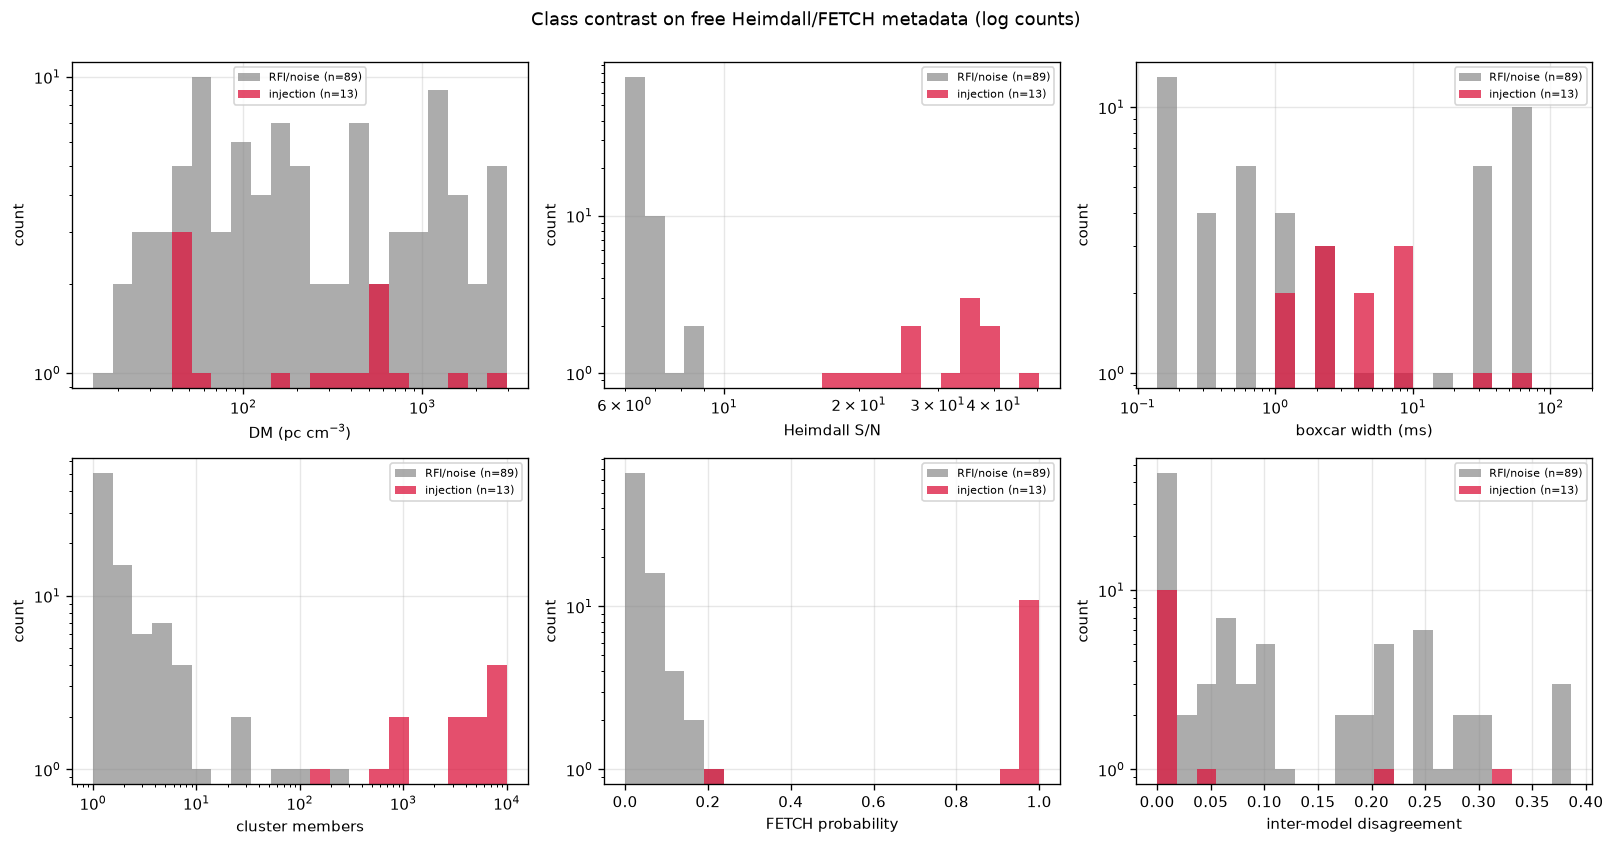

Single-feature separability (n_pos=13 - WIDE error bars, indicative only)


,feature,AUC,KS,p_MWU,pos_med,neg_med
1,snr_csv,1.0000,1.0000,0.0000,31.5808,6.2583
4,fetch_prob,1.0000,1.0000,0.0000,1.0000,0.0068
3,members,0.9991,0.9888,0.0000,4499.0000,1.0000
5,fetch_prob_std,0.2092,0.6041,0.0007,0.0001,0.0153
2,boxcar_ms,0.3803,0.4097,0.1512,4.4237,70.7789
0,dm_csv,0.5246,0.1772,0.7787,313.7340,197.0760


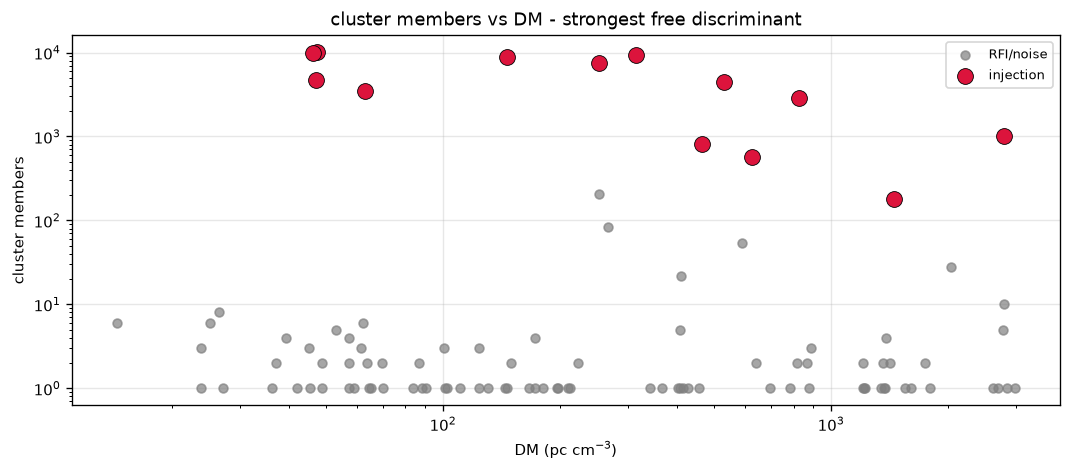

saved class_contrast_metadata.png, members_vs_dm.png


In [12]:
from sklearn.metrics import roc_auc_score
from scipy.stats import mannwhitneyu, ks_2samp
pos = cands[cands.is_injection]; neg = cands[~cands.is_injection]
specs = [("dm_csv", "DM (pc cm$^{-3}$)", True), ("snr_csv", "Heimdall S/N", True),
         ("boxcar_ms", "boxcar width (ms)", True), ("members", "cluster members", True),
         ("fetch_prob", "FETCH probability", False),
         ("fetch_prob_std", "inter-model disagreement", False)]
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.0))
for ax, (col, lab, logx) in zip(axes.ravel(), specs):
    v = cands[col].replace(0, np.nan) if logx else cands[col]
    lo, hi = float(np.nanmin(v)), float(np.nanmax(v))
    bins = (np.logspace(np.log10(max(lo, 1e-9)), np.log10(hi), 22) if logx
            else np.linspace(lo, hi, 22))
    ax.hist(neg[col], bins=bins, color="grey", alpha=.65, label=f"RFI/noise (n={len(neg)})")
    ax.hist(pos[col], bins=bins, color="crimson", alpha=.75, label=f"injection (n={len(pos)})")
    if logx: ax.set_xscale("log")
    ax.set_yscale("log"); ax.set(xlabel=lab, ylabel="count"); ax.legend(fontsize=6.5)
fig.suptitle("Class contrast on free Heimdall/FETCH metadata (log counts)", y=1.00)
fig.tight_layout(); fig.savefig(OUT_DIR / "class_contrast_metadata.png", bbox_inches="tight")
plt.show()

sep = []
for col, lab, _ in specs:
    a, bb = pos[col].dropna(), neg[col].dropna()
    if len(a) < 2 or len(bb) < 2: continue
    ok = cands[col].notna()
    sep.append({"feature": col,
                "AUC": roc_auc_score(cands.loc[ok, "is_injection"], cands.loc[ok, col]),
                "KS": ks_2samp(a, bb).statistic,
                "p_MWU": mannwhitneyu(a, bb, alternative="two-sided").pvalue,
                "pos_med": a.median(), "neg_med": bb.median()})
sep = pd.DataFrame(sep).sort_values("AUC", key=lambda x: (x - .5).abs(), ascending=False)
print(f"Single-feature separability (n_pos={len(pos)} - WIDE error bars, indicative only)")
display(sep.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(neg.dm_csv, neg.members, s=28, c="grey", alpha=.7, label="RFI/noise")
ax.scatter(pos.dm_csv, pos.members, s=90, c="crimson", edgecolor="k", lw=.5, label="injection")
ax.set(xscale="log", yscale="log", xlabel="DM (pc cm$^{-3}$)", ylabel="cluster members",
       title="cluster members vs DM - strongest free discriminant")
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(OUT_DIR / "members_vs_dm.png", bbox_inches="tight"); plt.show()
print("saved class_contrast_metadata.png, members_vs_dm.png")

## Recovery diagnostics

Red X marks rejected by FETCH. There's no Heimdall miss to mark, because it found all 13. The only loss in the whole chain is at the classifier.

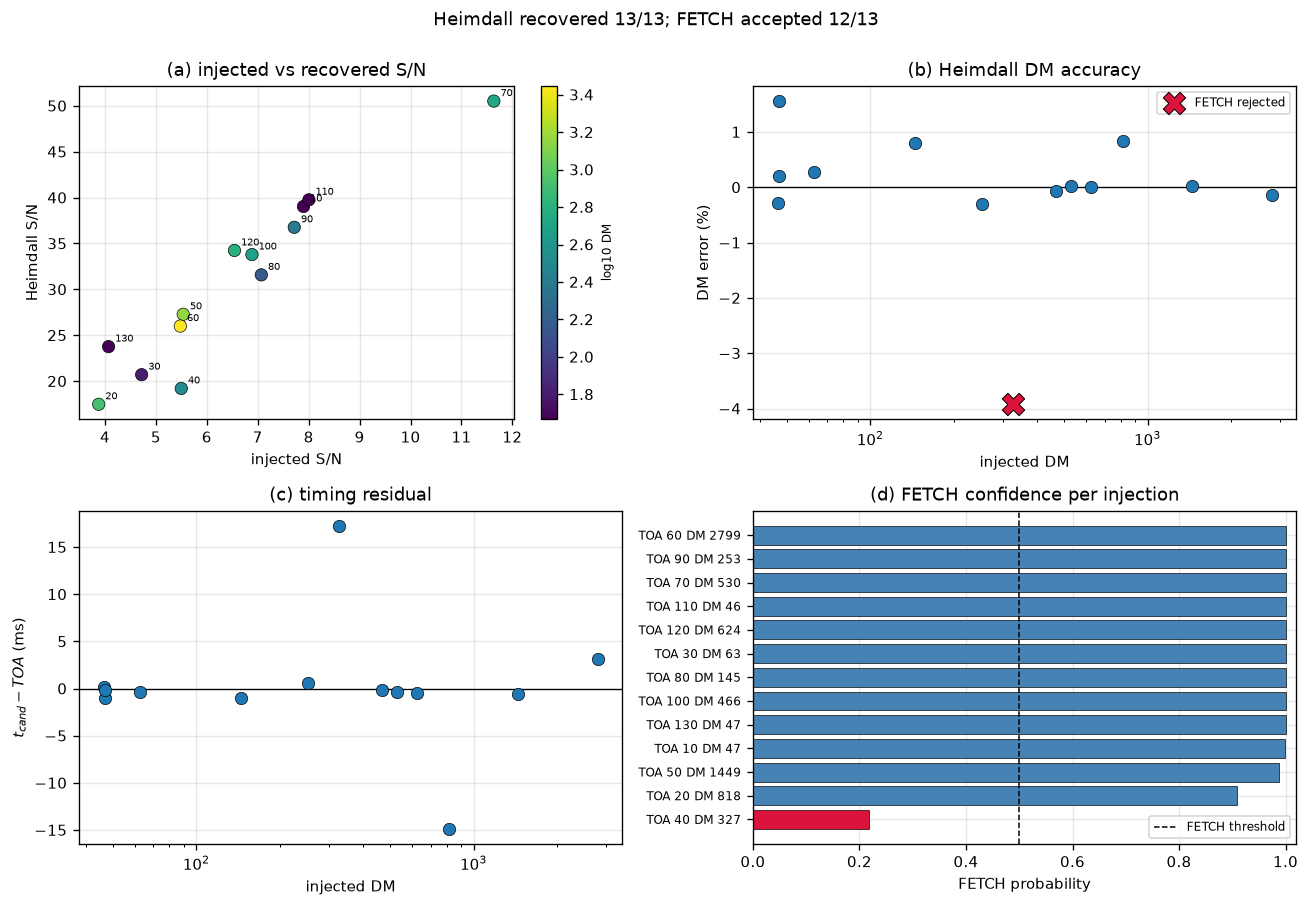

saved recovery_diagnostics.png


In [13]:
acc_df = match[match.fetch_ok]; rej_df = match[~match.fetch_ok]
fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
sc = ax[0,0].scatter(match.snr_inj, match.snr_heimdall, c=np.log10(match.dm_inj),
                     cmap="viridis", s=55, edgecolor="k", linewidth=.4, zorder=3)
for _, q in match.iterrows():
    ax[0,0].annotate(f"{q.TOA:.0f}", (q.snr_inj, q.snr_heimdall), fontsize=6,
                     xytext=(4, 3), textcoords="offset points")
ax[0,0].set(xlabel="injected S/N", ylabel="Heimdall S/N", title="(a) injected vs recovered S/N")
fig.colorbar(sc, ax=ax[0,0]).set_label("log10 DM", fontsize=7)

ax[0,1].axhline(0, color="k", lw=.8)
ax[0,1].scatter(match.dm_inj, match["dm_err_%"], s=55, edgecolor="k", linewidth=.4, zorder=3)
if len(rej_df):
    ax[0,1].scatter(rej_df.dm_inj, rej_df["dm_err_%"], s=180, marker="X", c="crimson",
                    edgecolor="k", lw=.6, zorder=4, label="FETCH rejected")
    ax[0,1].legend(fontsize=7)
ax[0,1].set(xscale="log", xlabel="injected DM", ylabel="DM error (%)",
            title="(b) Heimdall DM accuracy")

ax[1,0].axhline(0, color="k", lw=.8)
ax[1,0].scatter(match.dm_inj, match.dt_s * 1e3, s=55, edgecolor="k", linewidth=.4, zorder=3)
ax[1,0].set(xscale="log", xlabel="injected DM", ylabel="$t_{cand}-TOA$ (ms)",
            title="(c) timing residual")

o = match.sort_values("fetch_prob")
ax[1,1].barh(range(len(o)), o.fetch_prob,
             color=["steelblue" if k else "crimson" for k in o.fetch_ok],
             edgecolor="k", linewidth=.4)
ax[1,1].axvline(0.5, color="k", ls="--", lw=.9, label="FETCH threshold")
ax[1,1].set_yticks(range(len(o)))
ax[1,1].set_yticklabels([f"TOA {t:.0f} DM {d:.0f}" for t, d in zip(o.TOA, o.dm_inj)], fontsize=7)
ax[1,1].set(xlim=(0, 1.02), xlabel="FETCH probability", title="(d) FETCH confidence per injection")
ax[1,1].legend(fontsize=7)
fig.suptitle(f"Heimdall recovered {n_rec}/{len(match)}; "
             f"FETCH accepted {int(match.fetch_ok.sum())}/{len(match)}", y=1.00)
fig.tight_layout(); fig.savefig(OUT_DIR / "recovery_diagnostics.png", bbox_inches="tight")
plt.show(); print("saved recovery_diagnostics.png")

## Injection parameter space

Where the 13 sit against the instrument's own limits. The dashed line in the third panel is the smearing floor: nothing can be observed narrower than that no matter how sharp the pulse is.

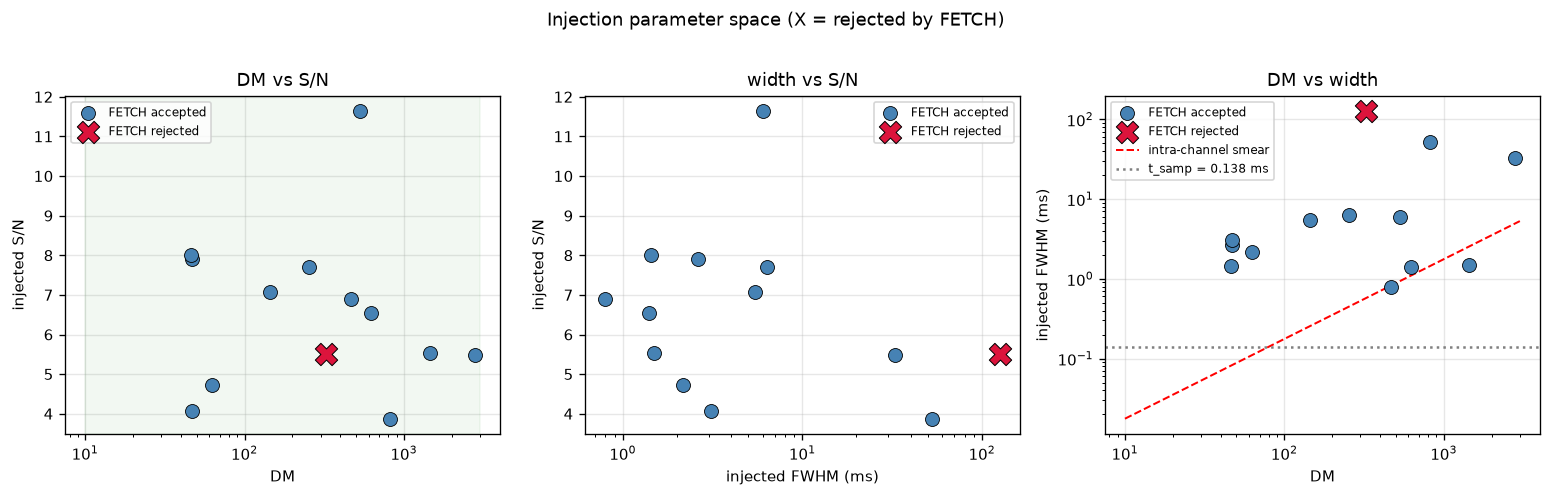

saved injection_parameter_space.png


In [14]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4.0))
def mark(a, xc, yc):
    a.scatter(acc_df[xc], acc_df[yc], s=70, c="steelblue", edgecolor="k", lw=.5,
              label="FETCH accepted", zorder=3)
    if len(rej_df):
        a.scatter(rej_df[xc], rej_df[yc], s=180, marker="X", c="crimson",
                  edgecolor="k", lw=.6, label="FETCH rejected", zorder=4)
mark(ax[0], "dm_inj", "snr_inj")
ax[0].set(xscale="log", xlabel="DM", ylabel="injected S/N", title="DM vs S/N")
ax[0].axvspan(DM_LOW, DM_MAX, color="green", alpha=.05)
mark(ax[1], "fwhm_inj_ms", "snr_inj")
ax[1].set(xscale="log", xlabel="injected FWHM (ms)", ylabel="injected S/N", title="width vs S/N")
mark(ax[2], "dm_inj", "fwhm_inj_ms")
dmg = np.logspace(np.log10(DM_LOW), np.log10(DM_MAX), 200)
ax[2].plot(dmg, dm_smear_chan_s(dmg, f_ctr, foff) * 1e3, "r--", lw=1.2, label="intra-channel smear")
ax[2].axhline(tsamp * 1e3, color="grey", ls=":", label=f"t_samp = {tsamp*1e3:.3f} ms")
ax[2].set(xscale="log", yscale="log", xlabel="DM", ylabel="injected FWHM (ms)", title="DM vs width")
for a in ax: a.legend(fontsize=7)
fig.suptitle("Injection parameter space (X = rejected by FETCH)", y=1.02)
fig.tight_layout(); fig.savefig(OUT_DIR / "injection_parameter_space.png", bbox_inches="tight")
plt.show(); print("saved injection_parameter_space.png")

## Smearing and boxcar budget

### The question
So why did FETCH reject the 40 s one?

### The numbers
`boxcar_frac` is how much of Heimdall's 1024-sample ceiling a pulse needs. The rejected injection needs **88.9%**. The widest one FETCH accepted needs **37.0%**. That's a 2.4x gap, and it's the widest injection in the set by about the same margin.

So FETCH struggles at the wide end. That's an opening for us: if a feature set handles wide pulses better, this is where it would show up. nb02 looks at that candidate's DM-SNR curve specifically.

Only 2 of the 13 are smearing-limited (DM 1449 and 465): the 465 one is sub-ms intrinsic, the 1449 one is 1.49 ms against 2.55 ms of smear. For the rest, the intrinsic width still dominates.

,TOA,dm_inj,snr_inj,fwhm_inj_ms,smear_ms,w_eff_ms,broadening,sweep_s,boxcar_samp,boxcar_frac,smear_limited,fetch_ok
0,10.000,46.746,7.898,2.623,0.082,2.628,1.002,0.084,19.012,0.019,False,True
1,20.003,818.105,3.877,52.321,1.441,52.341,1.000,1.475,378.621,0.370,False,True
2,30.005,62.885,4.720,2.156,0.111,2.163,1.003,0.113,15.646,0.015,False,True
3,40.008,326.542,5.498,125.784,0.575,125.785,1.000,0.589,909.906,0.889,False,False
4,50.011,1449.403,5.537,1.488,2.553,2.959,1.988,2.614,21.403,0.021,True,True
5,60.013,2799.174,5.479,32.970,4.931,33.337,1.011,5.048,241.152,0.235,False,True
6,70.016,530.203,11.636,6.033,0.934,6.107,1.012,0.956,44.176,0.043,False,True
7,80.019,144.810,7.070,5.475,0.255,5.483,1.001,0.261,39.662,0.039,False,True
8,90.021,252.525,7.717,6.371,0.445,6.388,1.003,0.455,46.211,0.045,False,True
9,100.024,465.575,6.886,0.796,0.820,1.151,1.446,0.840,8.327,0.008,True,True



boxcar ceiling: 1024 samples = 141.6 ms
smearing-limited injections: 2/13

FETCH-REJECTED TOA 40.008s: boxcar_frac 88.9% vs 37.0% for the widest accepted (ratio 2.40x)


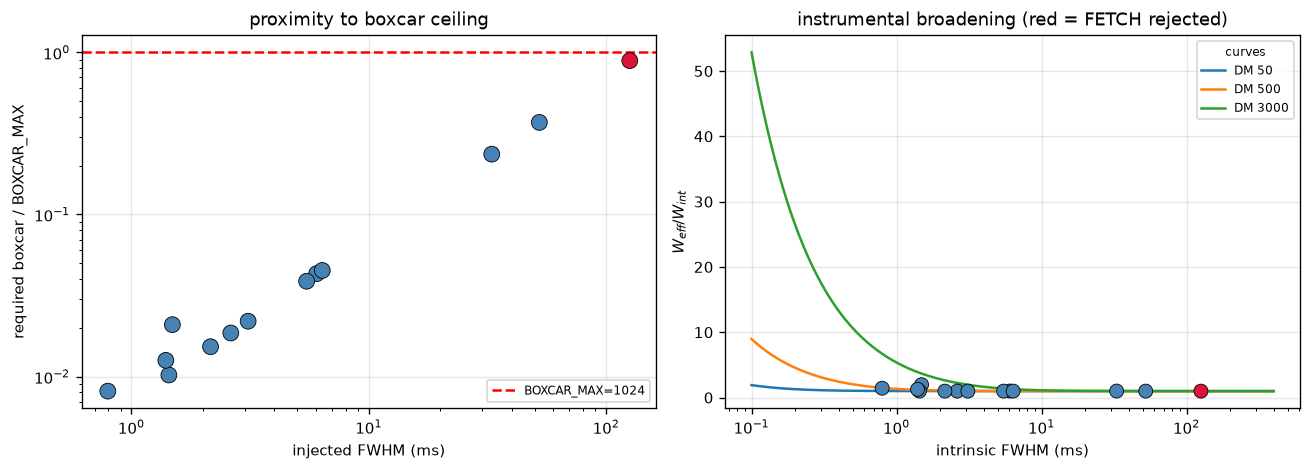

saved smearing_budget.png


In [15]:
b = match.copy()
b["smear_ms"]      = dm_smear_chan_s(b.dm_inj, f_ctr, foff) * 1e3
b["w_eff_ms"]      = w_eff_s(b.fwhm_inj_ms / 1e3, b.dm_inj, f_ctr, foff, tsamp) * 1e3
b["broadening"]    = b.w_eff_ms / b.fwhm_inj_ms
b["sweep_s"]       = dm_delay_s(b.dm_inj, f_hi, f_lo)
b["boxcar_samp"]   = b.w_eff_ms / 1e3 / tsamp
b["boxcar_frac"]   = b.boxcar_samp / BOXCAR_MAX
b["smear_limited"] = b.smear_ms > b.fwhm_inj_ms
display(b[["TOA","dm_inj","snr_inj","fwhm_inj_ms","smear_ms","w_eff_ms","broadening",
           "sweep_s","boxcar_samp","boxcar_frac","smear_limited","fetch_ok"]].round(3))
print(f"\nboxcar ceiling: {BOXCAR_MAX} samples = {BOXCAR_MAX*tsamp*1e3:.1f} ms")
print(f"smearing-limited injections: {int(b.smear_limited.sum())}/{len(b)}")
b_rej = b.loc[~b.fetch_ok]
if len(b_rej):
    nxt = b.loc[b.fetch_ok, "boxcar_frac"].max()
    for _, q in b_rej.iterrows():
        print(f"\nFETCH-REJECTED TOA {q.TOA:.3f}s: boxcar_frac {q.boxcar_frac:.1%} vs "
              f"{nxt:.1%} for the widest accepted (ratio {q.boxcar_frac/nxt:.2f}x)")
else:
    print("\nFETCH accepted every injection")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.0))
cc = np.where(b.fetch_ok, "steelblue", "crimson")
ax[0].scatter(b.fwhm_inj_ms, b.boxcar_frac, c=cc, s=90, edgecolor="k", lw=.5, zorder=3)
ax[0].axhline(1.0, color="r", ls="--", label=f"BOXCAR_MAX={BOXCAR_MAX}")
ax[0].set(xscale="log", yscale="log", xlabel="injected FWHM (ms)",
          ylabel="required boxcar / BOXCAR_MAX", title="proximity to boxcar ceiling")
ax[0].legend(fontsize=7)
wg = np.logspace(-1, 2.6, 300)
for dm_ in (50, 500, 3000):
    ax[1].plot(wg, w_eff_s(wg / 1e3, dm_, f_ctr, foff, tsamp) * 1e3 / wg, label=f"DM {dm_}")
ax[1].scatter(b.fwhm_inj_ms, b.broadening, c=cc, s=70, edgecolor="k", lw=.5, zorder=3)
ax[1].set(xscale="log", xlabel="intrinsic FWHM (ms)", ylabel="$W_{eff}/W_{int}$",
          title="instrumental broadening (red = FETCH rejected)")
ax[1].legend(fontsize=7, title="curves", title_fontsize=7)
fig.tight_layout(); fig.savefig(OUT_DIR / "smearing_budget.png", bbox_inches="tight")
plt.show(); print("saved smearing_budget.png")

## All 102 .h5 files

Three things to confirm.

| check | expectation |
|---|---|
| `std` on both images | 1.0 everywhere -> **dead feature** |
| `label` attr | 0 on every file, including known positives -> placeholder |
| `h5.width` vs `2**csv.width` | should agree on all 102 |

The `std == 1` one is important. candmaker normalises both images (`your.utils.math.normalise`: subtract the image **median**, divide by the image std), so `std` carries no information at all. `mean` survives, but as `(mean - median) / std` of the image before normalising, which is a pixel-skewness number rather than a brightness. That's the whole reason the
canonical 8 features have to be computed off **1-D collapsed curves** rather than the 2-D images.

**Corrected after nb02.** I originally wrote here that collapsing "puts real mean/std structure back", meaning both. That's only half right and nb02 measured it properly:

collapsing rescues `std`, `skewness` and `kurtosis`, but not `mean`. Collapsing by `mean` preserves the grand mean by construction, so the profile mean comes out numerically identical to the image mean, to about 5e-08. So two of the nominal eight (profile mean and DM-curve mean) are inherited normalisation artefacts, and worth checking before nb04.

nb02 also sharpens the `std` claim slightly: it's 1.0 to within float32 rounding, a total spread of about 2.2e-07, so `nunique()` will report 102 distinct values. That's the last couple of bits of a float32, not a range.

One more thing: the dimension labels differ between the two datasets.

`data_freq_time` is `[time, frequency]` but `data_dm_time` is `[dm, time]`. Integrated profile = collapse `freq_time` over frequency. DM-SNR curve = collapse `dm_time` over time. And as nb02 shows, that second one needs `max`, not `mean`. `mean` gives you a flat line and no error.

In [16]:
import h5py
SCALAR_ATTRS = ["tcand","dm","snr","width","label","nchans","nbits","tsamp","fch1","foff",
                "center_freq","bw","nspectra","time_decimation_factor",
                "frequency_decimation_factor","dm_opt","snr_opt","npol"]
recs = []
for p in H5_FILES:
    with h5py.File(p, "r") as f:
        a = f.attrs
        r = {"h5_name": p.name}
        r.update({k: (a[k].item() if isinstance(a[k], np.generic) else a[k])
                  for k in SCALAR_ATTRS if k in a})
        for ds in ("data_freq_time", "data_dm_time"):
            arr = f[ds][()]
            r[f"{ds}_shape"] = str(arr.shape)
            r[f"{ds}_std"]   = float(arr.std())
            r[f"{ds}_mean"]  = float(arr.mean())
            r[f"{ds}_min"]   = float(arr.min())
            r[f"{ds}_max"]   = float(arr.max())
            r[f"{ds}_dims"]  = ",".join(map(str, f[ds].attrs.get("DIMENSION_LABELS", [])))
        recs.append(r)
H = pd.DataFrame(recs)
print(f"read {len(H)} .h5 files\n")
for ds in ("data_freq_time", "data_dm_time"):
    sd = H[f"{ds}_std"]; mn = H[f"{ds}_mean"]
    flag = "CONSTANT 1.0 (dead feature)" if np.allclose(sd, 1.0, atol=1e-4) else "VARIES"
    print(f"{ds:16} std : min={sd.min():.6f} max={sd.max():.6f}  -> {flag}")
    print(f"{'':16} mean: min={mn.min():+.5f} max={mn.max():+.5f} std={mn.std():.5f}")
print(f"\nh5 'label' attr unique: {sorted(H['label'].unique())} -> "
      f"{'confirmed placeholder' if set(H['label'].unique())=={0} else 'UNEXPECTED'}")
w = cands[["h5_name","width","boxcar_samples"]].merge(H[["h5_name","width"]],
        on="h5_name", suffixes=("_csv","_h5"))
agree = (w.width_h5 == w.boxcar_samples)
print(f"\nh5.width == 2**csv.width : {int(agree.sum())}/{len(w)} agree")
if not agree.all(): display(w.loc[~agree].head(10))
print(f"\nh5 time_decimation_factor unique: {sorted(H['time_decimation_factor'].unique())}")
print(f"h5 frequency_decimation_factor unique: {sorted(H['frequency_decimation_factor'].unique())}")
print("(log reports freq=4, time=1..512 -> these attrs are stale, do not trust them)")
print(f"\ndata_freq_time dims: {list(H.data_freq_time_dims.unique())}")
print(f"data_dm_time   dims: {list(H.data_dm_time_dims.unique())}")
print(f"shapes: {list(H.data_freq_time_shape.unique())} / {list(H.data_dm_time_shape.unique())}")

read 102 .h5 files

data_freq_time   std : min=1.000000 max=1.000000  -> CONSTANT 1.0 (dead feature)
                 mean: min=-0.43304 max=+0.15402 std=0.11758
data_dm_time     std : min=1.000000 max=1.000000  -> CONSTANT 1.0 (dead feature)
                 mean: min=-0.64941 max=+0.12521 std=0.12832

h5 'label' attr unique: [np.int64(0)] -> confirmed placeholder

h5.width == 2**csv.width : 102/102 agree

h5 time_decimation_factor unique: [np.int64(1)]
h5 frequency_decimation_factor unique: [np.int64(1)]
(log reports freq=4, time=1..512 -> these attrs are stale, do not trust them)

data_freq_time dims: ['time,frequency']
data_dm_time   dims: ['dm,time']
shapes: ['(256, 256)'] / ['(256, 256)']


## Export

One labelled table with everything joined onto it. This is the artefact nb02-04 read, so nothing has to redo the cross-matching.

In [17]:
master = cands.merge(H.drop(columns=[c for c in ("tcand","dm","snr","width") if c in H.columns]),
                     on="h5_name", how="left")
# no absolute h5 path is stored: downstream notebooks rebuild it from config.CAND_DIR
lead = ["h5_name","is_injection","matched_TOA","fetch_label","fetch_prob",
        "fetch_prob_std","fetch_n_models_pos","tcand","dm_csv","snr_csv","width",
        "boxcar_samples","boxcar_ms","members","dm_trial","samp_idx","begin","end"]
master = master[[c for c in lead if c in master.columns] +
                [c for c in master.columns if c not in lead]]
master.to_csv(OUT_DIR / "candidates_labelled.csv", index=False)
M.to_csv(OUT_DIR / "fetch_model_probabilities.csv")
match.to_csv(OUT_DIR / "injection_recovery_match.csv", index=False)
b.to_csv(OUT_DIR / "smearing_budget.csv", index=False)
H.to_csv(OUT_DIR / "h5_attributes_all.csv", index=False)
sep.to_csv(OUT_DIR / "metadata_separability.csv", index=False)

summary = {
  "observation": config.CAND_DIR.name.split("_processed")[0] + "_processed",
  "instrument": INSTR,
  "search": {"DM_LOW": DM_LOW, "DM_MAX": DM_MAX, "DM_TOL": DM_TOL,
             "BOXCAR_MAX": BOXCAR_MAX, "boxcar_max_ms": BOXCAR_MAX * tsamp * 1e3},
  "counts": {"heimdall_raw_cand": int(len(cand_all)),
             "candmaker_input": int(len(allc)),
             "dropped_pre_candmaker": int(len(dropped)),
             "dropped_dm_range": ([float(dropped.dm.min()), float(dropped.dm.max())]
                                  if len(dropped) else None),
             "h5_written": int(len(H)), "n_positive": int(n_pos), "n_negative": int(n_neg),
             "positive_fraction": float(n_pos / len(cands)),
             "injections_total": int(len(inj)),
             "heimdall_recovered": int(n_rec),
             "fetch_accepted": int(match.fetch_ok.sum())},
  "fetch_vs_truth": {"n_models": int(M.shape[1]), "ensemble": "arithmetic mean of a..k",
                     "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
                     "recall": float(rec_), "precision": float(prec),
                     "specificity": float(spec), "g_mean": float(np.sqrt(rec_ * spec))},
  "labelling": {"TOL_T_S": TOL_T_S, "TOL_DM_FR": TOL_DM_FR,
                "source": "stime x DM cross-match against inj_params.csv TOA"},
  "metadata_separability": sep.to_dict("records"),
  "traps_confirmed": {"h5_label_attr_all_zero": bool(set(H["label"].unique()) == {0}),
                      "h5_decimation_attrs_stale": True,
                      "image_std_is_unity": bool(np.allclose(H.data_freq_time_std, 1.0, atol=1e-4)
                                            and np.allclose(H.data_dm_time_std, 1.0, atol=1e-4)),
                      "fetch_label_is_prediction_not_truth": True,
                      "candmaker_flag_rfi": False},
  "chunk_geometry_vs_log": f"{int(ok.sum())}/{len(cands)} exact",
  "open": ["DM-trial range of data_dm_time not recorded anywhere -> notebook 02",
           "single observation only; separability CIs are wide -> 20-obs pull"],
}
(OUT_DIR / "nb01_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps(summary, indent=2, default=str)[:2200])
print(f"\nwrote {len(master)} labelled candidates -> {OUT_DIR/'candidates_labelled.csv'}")

# provenance: package versions, run config and input hashes, so a rerun can be checked
hashes = {p.name: provenance.sha256(p) for p in (FIL_PATH, INJ_CSV, RESULTS_MULTI, ALL_CAND_CSV)}
provenance.write_environment(OUT_DIR, hashes)
print("wrote environment.json with sha256 of", list(hashes))

{
  "observation": "CUT_P_110_inj_13_processed",
  "instrument": {
    "source_name": "SGR0501+4516",
    "ra_deg": 75.27833333333335,
    "dec_deg": 45.27611111111111,
    "mjd_start": 60356.79948498255,
    "nchans": 1024,
    "nbits": 16,
    "itemsize_bytes": 2,
    "tsamp_s": 0.00013824,
    "tsamp_us": 138.24,
    "fch1_MHz": 415.85445601851853,
    "foff_MHz": -0.014467592592592591,
    "f_hi_MHz": 415.85445601851853,
    "f_lo_MHz": 401.0541087962963,
    "f_ctr_MHz": 408.4542824074074,
    "bandwidth_MHz": 14.814814814814813,
    "header_bytes": 327,
    "nsamples": 1012964,
    "duration_s": 140.03214336,
    "band_descending": true
  },
  "search": {
    "DM_LOW": 10.0,
    "DM_MAX": 3000.0,
    "DM_TOL": 1.01,
    "BOXCAR_MAX": 1024,
    "boxcar_max_ms": 141.55776
  },
  "counts": {
    "heimdall_raw_cand": 106,
    "candmaker_input": 102,
    "dropped_pre_candmaker": 4,
    "dropped_dm_range": [
      10.6113,
      11.0482
    ],
    "h5_written": 102,
    "n_positive": 1

wrote environment.json with sha256 of ['CUT_P_110_inj_13_processed.fil', 'CUT_P_110_inj_params.csv', 'Results_MULTI.csv', '2024-02-16-18-12-59_all_candidates.csv']
